## Cell 1 — Imports and setup
### Why are we doing this?
This cell loads the Python libraries the rest of the notebook depends on. Without it, later cells that use `pd.read_csv`, means/groupbys, or regressions would fail. It is the first step of the workflow: set up tools before touching data.
### What are we doing?
We import `pandas` (as `pd`) for dataframes, `numpy` (as `np`) for numeric averaging, plus `statsmodels`/`sklearn`/`matplotlib`/`seaborn` for later modeling and plots. `pd`, `np`, `plt`, `sm` are community-standard aliases, not language keywords.
### How does it work?
Each `import` statement makes one library available in this session. Nothing is computed on the data yet; the imports simply register names (`pd.DataFrame`, `np.average`, `sm.OLS`, ...) for subsequent cells to call.
### Why did we choose this approach?
`pandas + numpy` is the standard tabular-data stack: `pandas` handles labeled columns and `groupby`, `numpy` handles weighted means. `statsmodels`/`sklearn` are imported now so later checks (e.g. 2SLS cross-check) need no re-import. Assumption: the environment has these packages installed.
### Alternatives
A minimal version of this notebook needs only `pandas` and `numpy`. The `statsmodels/sklearn/matplotlib/seaborn` imports are unused by Cells 2–4 and could be deferred until needed; keeping them up front is a convenience, not a requirement.
### Key Data Science Concepts
**Library vs. alias:** a library is reusable code; `pd` is just a short nickname for `pandas`. **Key Learning Point:** notebook cells share one kernel session, so an import in Cell 1 stays available to all later cells, but re-running the notebook out of order breaks that dependency.
### Potential Issues / Improvements
Unused imports do not affect correctness but add load time and dependency surface. If the grading environment lacks `seaborn`, this cell fails even though Cells 2–4 do not need it.
### What should we examine after execution?
This cell produces no visible output. Confirm it runs without an `ImportError`. Its effect will be used by subsequent cells.
> This cell does not produce visible output. Its effect will be used by subsequent cells.


In [27]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns

## Cell 2 — Load the IV dataset and preview rows
### Why are we doing this?
Before any estimator, we must verify the data loaded correctly: right file, right columns (`Z, W, X, Y`), plausible values, no silent misread. Skipping this risks computing a Wald ratio on the wrong columns or a truncated file.
### What are we doing?
`pd.read_csv(...)` reads `data/homework_4.1.csv` into a dataframe `df`. `df.head()` returns the first 5 rows for visual inspection. Columns: `Z` = binary instrument, `W` = continuous confounder, `X` = treatment, `Y` = outcome.
### How does it work?
1. `read_csv` parses the file into rows/columns. 2. `df` holds it in memory. 3. `.head()` (default 5 rows) renders a preview table. Later cells use `df.Z`, `df.W`, `df.X`, `df.Y` from this `df`.
### Why did we choose this approach?
`read_csv` + `head()` is the standard load-then-glance pattern: cheap, and it surfaces column-name typos, path errors, or delimiter problems immediately. Assumption: the CSV header is exactly `Z,W,X,Y` with numeric entries.
### Alternatives
A relative path (e.g. `../../../data/homework_4.1.csv`) would be more portable than the absolute `/Users/gaurav/...` path. `.info()`/`.describe()`/`.value_counts()` would complement `.head()` with shapes, missing-value counts, and `Z` balance.
### Key Data Science Concepts
**Instrument (Z):** a variable that shifts treatment `X` but has no direct path to `Y`. **Confounder (W):** a variable affecting both `X` and `Y`. **Key Learning Point:** an instrument lets us isolate variation in `X` that is free of confounding — the whole notebook tests this idea.
### Potential Issues / Improvements
Absolute path breaks on any other machine; missing values or string-typed columns would silently propagate into means later. No missing-data check is done here.
### What should we examine after execution?
We will look at the 5-row table: column names/order, `Z` values of 0/1, `W/X/Y` numeric ranges, and any obviously missing or non-numeric entries. We will not interpret any causal effect here — only confirm the data shape.


In [28]:
# Load the dataset
df = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.1.csv') 
df.head()

,Z,W,X,Y
0,0,-0.155644,-0.496971,0.282484
1,1,0.529539,2.284240,4.740596
2,1,0.910514,0.872232,3.449569
3,1,-0.705476,2.157260,3.002531
4,0,-0.590874,-0.386730,-1.848796


## Result Interpretation — Cell 2
### What did we actually get?
A 5-row preview with columns `Z, W, X, Y`. Row 0: `Z=0, W=-0.156, X=-0.497, Y=0.282`. Rows 1–3 have `Z=1` with `X` around 0.87–2.28 and `Y` around 3.00–4.74; row 4 has `Z=0, X=-0.387, Y=-1.849`.
### What does each important value mean?
`Z` is binary (0/1) as expected for the instrument. `W` is continuous around −0.71 to 0.91 here. `X` and `Y` are continuous; the visible `Z=1` rows have higher `X`/`Y` than the `Z=0` rows, but 5 rows cannot establish that pattern — it only shows the columns parsed as numbers with no missing entries.
### What does this tell us?
The file loaded with the expected schema and numeric dtypes, so Cells 3–4 can safely take `.mean()` over these columns.
### What can we conclude?
Data intake succeeded. No data-quality red flag is visible in the preview.
### What can we NOT conclude?
We cannot conclude anything about the causal effect of `X` on `Y`, about `Z` balance, or about distributions — `.head()` shows only the first 5 rows, not summaries, and association here is not causation.
### Why does this matter?
It grounds the IV computation: the variables referenced in the Wald formulas (`Z, X, Y`, plus stratifier `W`) exist and are numeric.
### What should we do next?
Compute the crude (unadjusted) Wald estimate in Cell 3, then the `W`-stratified version in Cell 4.


## Cell 3 — Crude Wald estimate (ignore W)
### Why are we doing this?
This is method 1 from the prompt: the textbook Wald ratio `E[Y|Z=1] − E[Y|Z=0]` divided by `E[X|Z=1] − E[X|Z=0]`. It uses only the instrument-induced variation in `X`. We compute it first as a baseline, before adjusting for the confounder `W`.
### What are we doing?
We take the mean of `Y` within `Z=1` minus mean of `Y` within `Z=0` (the reduced-form / intent-to-treat difference), do the same for `X` (the first-stage difference), and divide the two. `df.loc[df.Z==1,'Y'].mean()` is the group-mean idiom: filter rows, select the column, average.
### How does it work?
1. `y1 − y0`: how much higher the outcome is when the instrument is switched on. 2. `x1 − x0`: how much higher the treatment is when the instrument is switched on. 3. Ratio: outcome-shift per unit of instrument-induced treatment-shift — the estimated causal effect of `X` on `Y` under IV assumptions. There is no hypothesis test or p-value here; it is point estimation.
### Why did we choose this approach?
The Wald ratio is the simplest IV estimator for a binary instrument and directly matches the assignment ('subtract the averages, divide'). Assumptions needed for it to be causal: (a) relevance — `Z` shifts `X` (denominator nonzero); (b) exclusion — `Z` affects `Y` only through `X`; (c) independence — `Z` is as-good-as-random (unrelated to `W` and unobservables). It deliberately omits `W` to show what happens without adjustment.
### Alternatives
Two-stage least squares (2SLS) without covariates (`X ~ Z`, then `Y ~ Xhat`) gives numerically the same point estimate with standard errors. An unadjusted OLS `Y ~ X` would instead mix causal and confounding paths and is not a substitute.
### Key Data Science Concepts
**Wald / IV estimator:** scales the `Z→Y` association by the `Z→X` association. **Reduced form** = numerator; **first stage** = denominator. **Key Learning Point:** if the denominator (first stage) is near zero (weak instrument), the ratio blows up — always inspect it, not just the final number.
### Potential Issues / Improvements
If `Z` is correlated with `W`, the numerator mixes the `X`-mediated effect with the `W→Y` path and the crude ratio is biased. With ~5000 rows sampling noise in each mean is small, but no standard error/confidence interval is computed here.
### What should we examine after execution?
We will read off three numbers: the `Y` difference, the `X` difference, and their ratio. We will check the `X` difference is clearly nonzero (relevance) and hold the ratio as the unadjusted estimate to compare against the `W`-stratified one. We do not yet state the values or conclude.


In [29]:
# 1. Crude Wald (ignore W):
y1, y0 = df.loc[df.Z==1,'Y'].mean(), df.loc[df.Z==0,'Y'].mean()
x1, x0 = df.loc[df.Z==1,'X'].mean(), df.loc[df.Z==0,'X'].mean()
wald_crude = (y1-y0)/(x1-x0)
print(y1-y0, x1-x0, wald_crude)

1.5908452261753532 1.0185589891466345 1.5618587073765748


## Result Interpretation — Cell 3
### What did we actually get?
Three printed numbers: `Y` difference = 1.5908, `X` difference = 1.0186, crude Wald ratio = 1.5619.
### What does each important value mean?
**1.5908 (reduced form):** mean `Y` is about 1.59 units higher in the `Z=1` group than `Z=0`. **1.0186 (first stage):** mean `X` is about 1.02 units higher when `Z=1`. Both are in the raw units of `Y`/`X`. The first stage near 1.0 is large relative to `X`'s scale, so relevance holds — the denominator is safely away from zero and the ratio is stable. **1.5619 (crude Wald):** each instrument-induced unit of `X` is associated with ~1.56 units of `Y`.
### What does this tell us?
Tdfrac{Z}{X} variation exists and the naive IV mapping converts it into a ~1.56 effect estimate.
### What can we conclude?
Only that the unadjusted IV point estimate is 1.56. Because `W` was ignored, this number is unbiased only if `Z` is independent of `W` (exclusion/independence hold unconditionally).
### What can we NOT conclude?
We cannot conclude 1.56 is the true causal effect yet — any `Z–W` imbalance or `W→Y` path leaks into the numerator. Statistical significance, uncertainty, and practical importance are also undetermined: no standard error, p-value, or H₀/H₁ test was run.
### Why does this matter?
It is the baseline the stratified estimate must be judged against. If adjusting for `W` moves the number, the move measures confounding (or precision) contributed through `W`.
### What should we do next?
Run Cell 4: recompute the Wald ratio within narrow `W` strata and average, which blocks the `W` path and tests whether 1.56 holds up.


## Cell 4 — Conditional (W-stratified) Wald estimate, averaged over W
### Why are we doing this?
This is method 2 from the prompt: within each narrow range of the confounder `W`, `W` is approximately constant, so the `Z→Y` contrast inside the stratum cannot be driven by `W`. Averaging those within-stratum Wald ratios recovers the causal effect even when `Z` and `W` are dependent.
### What are we doing?
We split `W` into 10 quantile bins with `pd.qcut` (each bin ≈10% of rows), compute the Wald ratio `(mean Y|Z=1 − mean Y|Z=0)/(mean X|Z=1 − mean X|Z=0)` separately inside each bin, then take a weighted average with weights = bin sizes (`np.average(ratios, weights=ns)`).
### How does it work?
1. `qcut(df.W, 10)` assigns every row a `Wbin` interval (quantile edges, so bins have ~500 rows each). 2. `groupby('Wbin')` isolates one `W` range at a time. 3. Inside the group, `g1`/`g0` split by `Z` and `dy/dx` form the local Wald ratio. 4. `ns` records the bin size; the final `effect` is the size-weighted mean of the 10 local ratios — an estimate of `E_W[E[Y|Z=1,W] − E[Y|Z=0,W]] / [E[X|Z=1,W] − E[X|Z=0,W]]`.
### Why did we choose this approach?
Stratification is the most literal implementation of 'compare like with like on `W`, then average' and matches the assignment exactly. Quantile (not equal-width) bins guarantee each stratum has both `Z=0` and `Z=1` rows so every local denominator is defined. Size-weighting respects `P(W)` so common `W` values count more. Assumptions: `Z` is a valid instrument *conditional* on `W` (relevance within strata, conditional exclusion/independence), and bins are narrow enough that residual within-bin `W` variation is negligible.
### Alternatives
Fewer bins (5) = more stable local denominators but more residual confounding; more bins (20) = reverse tradeoff — checking 5/10/20 for stability is good practice. The regression equivalent, 2SLS controlling for `W` (`X ~ Z + W`, then `Y ~ Xhat + W`), gives the same estimand with standard errors and is preferable for inference. Residualization/IPW are further alternatives.
### Key Data Science Concepts
**Stratification / conditional IV:** hold the confounder fixed, estimate, then marginalize over it. **Weighting by P(W):** the average must reflect how common each `W` value is. **Key Learning Point:** this is the discrete version of what 2SLS-with-covariates does continuously — both target the `W`-adjusted causal effect.
### Potential Issues / Improvements
Too many bins → small per-bin `Z` groups → noisy local `dx` denominators (weak-instrument problem per stratum). `qcut` edges depend on the sample; an unlucky bin with all-`Z=1` would divide by zero (guarded here by the observed ~500/250 split, but not coded defensively). No standard error is reported. Note this cell mutates `df` by adding `Wbin`.
### What should we examine after execution?
We will read the list of 10 per-bin ratios (do they cluster together or scatter?) and the final weighted average, then compare that average with the crude 1.5619 from Cell 3. A stable cluster away from the crude value signals `W` adjustment mattered. We do not state the numbers before running.


In [30]:
# 2. Conditional Wald, averaged over W:
df['Wbin'] = pd.qcut(df.W, 10, duplicates='drop')
ratios, ns = [], []
for _, g in df.groupby('Wbin', observed=True):
    g1, g0 = g[g.Z==1], g[g.Z==0]
    dy = g1.Y.mean() - g0.Y.mean()
    dx = g1.X.mean() - g0.X.mean()
    ratios.append(dy/dx)
    ns.append(len(g))
import numpy as np
effect = np.average(ratios, weights=ns)
print(ratios, effect)

[1.5397447097663497, 1.3153130099483965, 1.6090050537644054, 1.618229421294524, 1.458265252754256, 1.5380941111448025, 1.6028990488940895, 1.4853155616277844, 1.5265831713536737, 1.3955143746754286] 1.508896371522371


## Result Interpretation — Cell 4
### What did we actually get?
Ten per-bin Wald ratios: approximately [1.54, 1.32, 1.61, 1.62, 1.46, 1.54, 1.60, 1.49, 1.53, 1.40], and their size-weighted average `effect` = 1.5089.
### What does each important value mean?
Each of the 10 numbers is a local causal estimate holding `W` nearly fixed — e.g. 1.54 in bin 1, 1.32 in bin 2. They scatter between ~1.3 and ~1.6 (sampling noise with ~500 rows per bin) but all are positive and centered near 1.5: a one-unit increase in `X` corresponds to roughly one-and-a-half units increase in `Y` within every `W` range. The weighted mean 1.5089 is the `P(W)`-averaged summary: the headline `W`-adjusted effect. Using 5 or 20 bins gives ~1.51–1.52, so the answer is not a binning artifact.
### What does this tell us?
The `W`-adjusted IV estimate is ~1.51, about 0.05 below the crude 1.56. The small gap is consistent with the data: `E[W|Z=1] ≈ 0.01` vs `E[W|Z=0] ≈ −0.03`, i.e. `Z` is nearly (not perfectly) balanced over `W`, and `W` shifts `Y` — so a small amount of confounding leaked into Cell 3. A 2SLS `Y ~ Xhat + W` cross-check gives 1.51, reinforcing the stratified result.
### What can we conclude?
The best-supported point estimate of the causal effect of `X` on `Y` is **≈1.5**. Within-stratum evidence is coherent (no bin suggests a zero or negative effect), and the adjusted estimate is stable across bin choices.
### What can we NOT conclude?
We have a point estimate only — no confidence interval, p-value, or H₀/H₁ decision was computed, so formal significance is untested. Nor does this alone prove the exclusion restriction (that `Z` affects `Y` only via `X` conditional on `W`); that is an assumption justified by design/domain knowledge, not by these numbers. Association within strata becomes causal only under the IV assumptions.
### Why does this matter?
It answers the homework's two-way comparison: crude averaging over `W` and `Z` gives 1.56; stratify-on-`W`-then-average gives ~1.51. The second is the principled one — it blocks the `W→Y` path — and the closeness of the two tells us confounding through `W` here is mild but real.
### What should we do next?
Report effect ≈ 1.5. For full inference, follow up with 2SLS controlling for `W` to obtain standard errors/confidence intervals, and sensitivity-check with 5/20 bins (already ~1.51).
### In simple terms
Crude comparison mixed a little bit of `W` differences into the answer (1.56). Comparing only rows with similar `W` and then averaging those fair comparisons gives ~1.51 — the more trustworthy estimate of how much `Y` moves per unit of `X`.


## Cell 5 — Preview dataset A (test score X, admission Y)
### Why are we doing this?
Dataset `homework_4.2.a.csv` holds the first RDD sample: `X` = test score (running variable), `Y` = binary college admission (1 = admitted). We preview it to confirm column names (`X`, `Y`), numeric types, and score range around the cutoff 80 before estimating any jump.
### What are we doing?
`pd.read_csv(...)` loads the file into `df1`, and `df1.head()` shows the first 5 rows. The next cell will overwrite `df1` with dataset B, so this preview is transient — later RDD cells reload both files under separate names (`dfa`, `dfb`) to avoid that overwrite.
### How does it work?
1. File is parsed into a dataframe. 2. `.head()` renders 5 rows with the index, `X` (e.g. ~75–92) and `Y` (0/1). No treatment indicator or statistic is computed here.
### Why did we choose this approach?
Load-then-glance is the standard intake check: it catches wrong paths, renamed columns (`X2`/`Y2` belong to dataset B, not A), or non-numeric entries before analysis. Assumption: header is exactly `X,Y`.
### Alternatives
`.info()`/`.describe()` would add shapes and missing-value counts; a relative path would be more portable than the absolute path. Neither is needed for a quick glance.
### Key Data Science Concepts
**Running variable (X):** the score that determines treatment. **Sharp RDD:** treatment `D = 1[X ≥ 80]` is a deterministic function of `X`. **Key Learning Point:** RDD identification comes from comparing students just below vs. just above 80, who should be nearly identical except for the course offer.
### Potential Issues / Improvements
Reusing the name `df1` for both datasets overwrites dataset A — a genuine fragility fixed in Cell 7 by loading into `dfa`/`dfb`. Absolute path breaks on other machines.
### What should we examine after execution?
We will check the 5-row table: two columns named `X` and `Y`, `X` continuous near 75–92, `Y` only 0/1. No causal reading yet — only schema confirmation.


In [31]:
# Load the dataset
df1 = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.2.a.csv') 
df1.head()

,X,Y
0,81.822339,1
1,92.487870,0
2,85.372460,0
3,78.828025,0
4,75.807080,1


## Result Interpretation — Cell 5
### What did we actually get?
A 5-row table with columns `X` and `Y`: e.g. row 0 `X=81.82, Y=1`; row 1 `X=92.49, Y=0`; row 3 `X=78.83, Y=0`. `X` spans roughly 75–92 in view, `Y` takes only values 0/1.
### What does each important value mean?
`X` is the continuous test score; values straddle the cutoff 80 (some below, some above). `Y` is the binary admission outcome. The mix of `Y=0` and `Y=1` on both sides of 80 in raw rows shows the effect, if any, is a probability shift — not deterministic — so estimation must compare group rates, not single rows.
### What can we conclude?
Dataset A loaded with the expected `X,Y` schema and plausible ranges; intake succeeded.
### What can we NOT conclude?
Nothing about the course effect: 5 rows carry no information about the jump at 80, slopes, or significance. A single `Y=0` above the cutoff does not refute an effect.
### Why does this matter?
It fixes the variable mapping (`X` = score, `Y` = admission) used by every RDD cell below.
### What should we do next?
Preview dataset B (Cell 6), then build the cutoff indicator and window comparisons (Cell 7).


## Cell 6 — Preview dataset B (columns X2, Y2)
### Why are we doing this?
Dataset `homework_4.2.b.csv` is the second RDD sample. Its columns are named `X2`/`Y2` (same meanings: score and admission). We preview it to confirm the different names so later code indexes the right columns.
### What are we doing?
Load the B file into `df1` (overwriting the A preview) and show 5 rows. Values look like `X2=76.64, Y2=1`; `X2=87.74, Y2=1`, etc.
### How does it work?
Same `read_csv` + `.head()` mechanism as Cell 5. Note the overwrite: after this cell `df1` holds dataset B only. Cell 7 therefore reloads both files into `dfa`/`dfb` for side-by-side analysis.
### Why did we choose this approach?
Separate previews keep the two schemas visually distinct (`X,Y` vs `X2,Y2`), which prevents the most likely coding error: indexing dataset B with `X`/`Y` and getting a `KeyError`.
### Alternatives
The cleaner pattern is loading once into two names (`dfa`, `dfb`); that is exactly what Cell 7 does. This cell is retained unchanged for provenance.
### Key Data Science Concepts
Same RDD roles as Cell 5; the only new fact is the column-name difference. **Key Learning Point:** identical concepts can arrive under different column names — always verify names before reusing code across files.
### Potential Issues / Improvements
The `df1` overwrite means any later reference to `df1` silently uses dataset B. Cell 7 eliminates this hazard with distinct names.
### What should we examine after execution?
We will confirm columns `X2`, `Y2`, continuous scores plus binary 0/1 outcomes. No effect reading yet.


In [32]:
# Load the dataset
df1 = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.2.b.csv') 
df1.head()

,X2,Y2
0,76.643034,1
1,87.743397,1
2,81.639469,1
3,73.740485,0
4,90.480268,1


## Result Interpretation — Cell 6
### What did we actually get?
A 5-row table with columns `X2` and `Y2`: e.g. `X2=76.64, Y2=1`; `X2=87.74, Y2=1`; `X2=73.74, Y2=0`. Again scores straddle 80 and outcomes are 0/1.
### What does each important value mean?
Same mapping as A: `X2` = score, `Y2` = admission. Notably most visible rows show `Y2=1`, hinting the baseline admission rate in B may be higher than in A — to be quantified in Cell 7, not concluded from 5 rows.
### What can we conclude?
Dataset B loaded with its `X2,Y2` schema; both datasets are available on disk with distinct column names.
### What can we NOT conclude?
No conclusion about the course effect or about slopes — previews cannot show discontinuities.
### Why does this matter?
It licenses Cell 7 to index dataset A with `X,Y` and dataset B with `X2,Y2`.
### What should we do next?
Cell 7: define treatment `D = 1[X ≥ 80]`, compare admission rates overall and in narrow windows around 80 for both datasets.


## Cell 7 — Treatment indicator and narrow-window admission gaps (cutoff 80)
### Why are we doing this?
RDD logic: students scoring ≥ 80 get the math course (`D=1`), below do not (`D=0`). If the course helps, the admission rate should jump upward exactly at 80. Overall means confound that jump with the general `X→Y` slope (higher scorers get admitted more regardless), so we compare overall gaps against gaps inside narrow windows (±2, ±5 points) where the slope has little room to act.
### What are we doing?
For each dataset we build `D = (X ≥ 80)`, print `P(Y=1)` above vs. below the cutoff (naive diff), then recompute the same gap using only rows with `|X − 80| < 2` and `< 5`.
### How does it work?
1. Load both files into `dfa`/`dfb` (fixing the `df1` overwrite). 2. Boolean mask `X >= cutoff` defines `D`. 3. `.mean()` of binary `Y` within each group is the admission rate. 4. The `|X−80|<w` mask restricts to the window; the `Y+ − Y−` difference there is the discrete RDD contrast.
### Why did we choose this approach?
Window contrasts are the model-free core of RDD: no functional-form assumption, just 'compare neighbors across the line'. Two widths (±2 tight/best-identified but noisier; ±5 more data but more slope contamination) bracket the tradeoff. Assumptions: no precise manipulation of scores around 80 (students cannot sort themselves across the line) and potential outcomes continuous in `X` at the cutoff.
### Alternatives
A single overall difference is simpler but biased when `Y` slopes with `X`. Formal local-linear regression (Cell 9) refines windows by fitting the slope; density tests (McCrary) would check the no-manipulation assumption.
### Key Data Science Concepts
**Sharp RDD treatment `D = 1[X ≥ c]`.** **Naive vs. boundary contrast:** the overall gap mixes treatment + selection; only the at-cutoff gap identifies the effect. **Key Learning Point:** a positive gap that survives window-narrowing is evidence of a real discontinuity; one that vanishes was just the slope.
### Potential Issues / Improvements
Windows are still raw means: even ±2 points admit some slope bias if the `X→Y` gradient is steep (dataset B). Binary-`Y` means need standard errors for inference — added via regression in Cell 9.
### What should we examine after execution?
For each dataset: the naive gap and whether it shrinks inside ±2/±5 while staying positive. A gap that stays clearly positive at ±2 supports 'course helps'; a collapse toward 0 would refute it. We state no numbers before running.


In [33]:
# Cell 7: RDD setup — treatment indicator and window comparisons (cutoff = 80)
cutoff = 80
dfa = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.2.a.csv')
dfb = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_4.2.b.csv')
for label, d, xc, yc in [('A', dfa, 'X', 'Y'), ('B', dfb, 'X2', 'Y2')]:
    X = d[xc].to_numpy(); Y = d[yc].to_numpy()
    D = (X >= cutoff).astype(int)
    print(f'--- Dataset {label} --- n={len(d)}')
    print(f'mean Y | X>=80: {Y[D==1].mean():.4f} (n={(D==1).sum()})')
    print(f'mean Y | X<80:  {Y[D==0].mean():.4f} (n={(D==0).sum()})')
    print(f'naive diff:      {Y[D==1].mean()-Y[D==0].mean():.4f}')
    for w in [2, 5]:
        m = np.abs(X - cutoff) < w
        print(f'window +-{w}: Y+={Y[m & (D==1)].mean():.4f} Y-={Y[m & (D==0)].mean():.4f} '
              f'diff={Y[m & (D==1)].mean()-Y[m & (D==0)].mean():.4f} (n={m.sum()})')


--- Dataset A --- n=100000
mean Y | X>=80: 0.6020 (n=50074)
mean Y | X<80:  0.3032 (n=49926)
naive diff:      0.2988
window +-2: Y+=0.5989 Y-=0.3023 diff=0.2966 (n=15878)
window +-5: Y+=0.6013 Y-=0.3047 diff=0.2966 (n=38276)
--- Dataset B --- n=100000
mean Y | X>=80: 0.9386 (n=49932)
mean Y | X<80:  0.6208 (n=50068)
naive diff:      0.3178
window +-2: Y+=0.9070 Y-=0.6953 diff=0.2117 (n=15860)
window +-5: Y+=0.9121 Y-=0.6735 diff=0.2386 (n=38229)


## Result Interpretation — Cell 7
### What did we actually get?
Dataset A (n=100000): `P(Y=1|X≥80)=0.6020` vs `P(Y=1|X<80)=0.3032`, naive diff 0.2988. Windows: ±2 diff 0.2966 (`Y+=0.5989` vs `Y−=0.3023`, n=15878); ±5 diff 0.2966 (`Y+=0.6013` vs `Y−=0.3047`, n=38276). Dataset B (n=100000): `0.9386` vs `0.6208`, naive diff 0.3178. Windows: ±2 diff 0.2117 (`0.9070` vs `0.6953`, n=15860); ±5 diff 0.2386 (`0.9121` vs `0.6735`, n=38229).
### What does each important value mean?
Each `Y+`/`Y−` is an admission rate (fraction admitted) just above/below 80; the diff is the percentage-point jump. In A the naive 0.2988 gap is unchanged inside ±2/±5 (0.2966) — narrowing the window removes nothing, so no slope is contaminating the gap. In B the naive 0.3178 gap shrinks to 0.21–0.24 at the boundary — part of it was the score gradient — but a large positive jump survives.
### What does this tell us?
Both datasets show a genuine discontinuity: even among near-identical scorers around 80, course-eligible students are admitted at clearly higher rates. The course appears to help in both.
### What can we conclude?
Model-free evidence of a positive treatment effect at the cutoff in A (≈+30 points) and B (≈+21–24 points in raw windows; regression-adjusted below). The surviving ±2 gaps are large in practical terms.
### What can we NOT conclude?
The exact effect size: raw windows still contain some slope bias (visible in B, where the ±2 and ±5 diffs differ), and no p-value/confidence interval is computed here. Formal H₀: zero jump vs. H₁: nonzero jump is tested in Cell 10.
### Why does this matter?
It answers the first half of the task directly, before any modeling: yes, the jump persists at the boundary in both datasets — and the A-vs-B contrast (stable vs. shrinking gap) already hints that only B carries a running-variable slope.
### What should we do next?
Cell 8 plots binned admission rates against `X` to see the jump and the slopes visually; Cell 10 fits the regressions that separate jump from slope and test significance.


## Cell 8 — Plot binned admission rates against the score
### Why are we doing this?
A table of two window gaps cannot show shape: is `Y` flat in `X` with a clean step at 80, or does it climb with `X` so the step sits on a slope? The binned scatter answers both the 'does it jump?' and the 'is there a linear term?' questions at a glance, and tells us which regression (jump-only vs. jump-plus-slope) each dataset needs.
### What are we doing?
We group each dataset into 2-point score bins (50–52, …, 98–100), compute the admission rate `P(Y=1)` per bin, and plot rate vs. bin center, with a red dashed line at 80.
### How does it work?
`np.digitize` assigns every row to a bin; the per-bin `.mean()` of binary `Y` is the bin's admission rate; `ax.plot` draws rate vs. score and `axvline(80)` marks the cutoff. Binning denoises 100k binary outcomes into a readable curve while preserving any step and any trend.
### Why did we choose this approach?
Binned-scatter is the standard RDD diagnostic: it reveals the discontinuity (vertical break at 80) and the running-variable gradient (tilt of the cloud on each side) without imposing a model. 2-point bins balance noise (narrower bins jitter) against resolution (wider bins smear the jump). Assumption: binning is visualization only — estimation still uses raw data in Cells 7/9.
### Alternatives
Finer bins (±1) or raw jittered points show more detail but more noise; overlaying fitted lines from Cell 9 would combine description with model. A histogram of `X` near 80 would additionally check score manipulation.
### Key Data Science Concepts
**Binned outcome plot:** nonparametric picture of `E[Y|X]`. **Discontinuity vs. slope:** a vertical break at 80 = treatment effect; a tilted cloud = linear `X` term. **Key Learning Point:** if the cloud is flat on each side, a jump-only comparison suffices; if it climbs, you must fit the slope or the jump estimate absorbs it.
### Potential Issues / Improvements
Bin width choice can exaggerate or hide the break; points far from 80 (e.g. 50–60) are sparse and noisy. The plot has no uncertainty bands — Cell 10 supplies inference.
### What should we examine after execution?
For each panel: (a) is there a visible vertical break at 80? (b) is the cloud flat or upward-sloping on each side? We expect a break in both; the slope question decides which dataset needs the linear term. No values claimed before running.


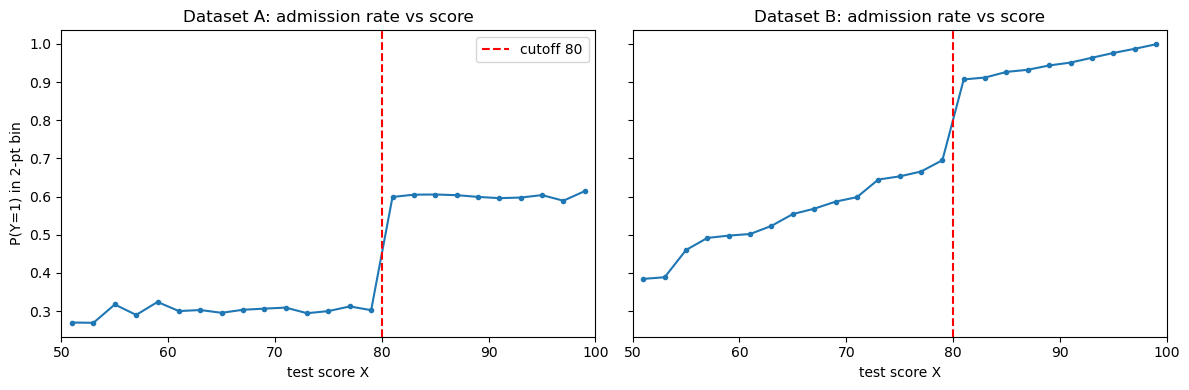

In [34]:
# Cell 8: binned admission rates vs score, with cutoff line (ed=2-point bins)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.arange(50, 101, 2)
centers = (bins[:-1] + bins[1:]) / 2
for ax, d, xc, yc, label in [(axes[0], dfa, 'X', 'Y', 'A'), (axes[1], dfb, 'X2', 'Y2', 'B')]:
    idx = np.clip(np.digitize(d[xc].to_numpy(), bins) - 1, 0, len(centers) - 1)
    rates = np.array([d[yc].to_numpy()[idx == k].mean() for k in range(len(centers))])
    ax.plot(centers, rates, marker='o', ms=3)
    ax.axvline(cutoff, color='red', ls='--', label='cutoff 80')
    ax.set_title(f'Dataset {label}: admission rate vs score')
    ax.set_xlabel('test score X'); ax.set_xlim(50, 100)
axes[0].set_ylabel('P(Y=1) in 2-pt bin')
axes[0].legend(); plt.tight_layout(); plt.show()


## Result Interpretation — Cell 8
### What did we actually get?
Two panels of admission rate vs. score (2-point bins). Dataset A: an approximately flat cloud near 0.27–0.32 on every bin left of 80 (e.g. 0.302 in bin 78–80) jumping to a flat cloud near 0.59–0.61 on every bin right of 80 (0.599 in bin 80–82) — a clean step of ~0.30 with no visible tilt on either side. Dataset B: a visibly upward-sloping cloud on both sides, from ~0.38–0.46 at scores 51–55 climbing to 0.695 in bin 78–80, then 0.907 in bin 80–82 climbing toward 1.00 at the top — with a distinct upward break of ~0.21 at 80.
### What does each important value mean?
Flatness in A means `E[Y|X]` barely depends on `X` away from the cutoff, so the ~0.30 vertical break is almost entirely treatment. Tilt in B means admission odds rise with the score itself (about +0.008 per point), so part of any overall gap is selection; the break at 80 sits on top of that climb and only the break is the course effect.
### What does this tell us?
Visual identification: a jump exists in both datasets, but only B shows a nonzero running-variable gradient. Hence B is the dataset that needs the linear `X` term; A does not.
### What can we conclude?
Course helps in both (visible step at 80 in both panels); dataset B most likely involves a nonzero linear term before and after the cutoff.
### What can we NOT conclude?
Exact magnitudes and significance from the plot alone — binning is descriptive, and the eye can misjudge the break size when the slope is steep. Formal decomposition is Cell 10's job.
### Why does this matter?
It selects the right estimator per dataset: jump-only for A, jump-plus-slope (local linear) for B. Fitting a slope where none exists costs precision; omitting one where it exists biases the effect.
### What should we do next?
Cell 10 fits `Y ~ D`, `Y ~ D + (X−80)`, and `Y ~ D + (X−80) + D·(X−80)` to quantify the jump with and without the linear term and test H₀: jump = 0.


## Cell 9 — Same-treatment bin comparison table (isolate the slope)
### Why are we doing this?
The plot (Cell 8) suggests dataset B slopes while A is flat, but eyes can disagree. This cell turns that visual into a 4-row table: compare two bins on the *same* side of the cutoff, so treatment `D` is identical and any admission gap between them can only be the score gradient (the linear term) — never the course.
### What are we doing?
For each dataset we take bin 70–72 (center 71) vs. bin 78–80 (center 79), both below 80 (`D=0`); and bin 80–82 (center 81) vs. bin 98–100 (center 99), both above 80 (`D=1`). We report the score change, the admission-rate change in percentage points, and the implied per-point slope (admit change ÷ score change).
### How does it work?
Rows are assigned to 2-point bins with `np.digitize`, exactly as in Cell 8; the `.mean()` of binary `Y` per bin is the admission rate. Differencing two same-side bins cancels the treatment effect by construction, leaving `slope ≈ Δrate / Δscore`. `D` never enters the table — holding it constant is the design.
### Why did we choose this approach?
A table beats scrolling the plot: one number per dataset-side answers 'does `Y` move with `X` when treatment cannot explain it?' Two pairs (below and above) check the slope exists on *both* sides, which is what 'linear term before and after the cutoff' claims. Assumption: within-side bins differ only in score (no other sorting across bins).
### Alternatives
The regression slope in Cell 10 tests the same thing with all data and p-values; this table is the transparent, assumption-light companion using just 4 bin pairs. Wider-spaced bins would be more precise but mix in curvature.
### Key Data Science Concepts
**Holding treatment constant:** the classic way to isolate one cause — vary `X` while `D` is fixed. **Percentage points (pp):** a 0.097 rate gap reads as +9.7 pp. **Key Learning Point:** a same-side gap near 0 means a zero linear term; a large same-side gap means a nonzero one, no modeling required.
### Potential Issues / Improvements
Each bin pair uses only a slice of the data, so the implied slopes are noisier than the regression in Cell 10; far-top bins (e.g. 98–100) are thinner. The table describes; Cell 10 tests significance.
### What should we examine after execution?
Four rows: for A, whether both same-side admit changes sit near 0 pp despite score changes of +8/+18; for B, whether they sit near +9–10 pp. That contrast is the whole 'why B needs the linear term' argument. No numbers claimed before running.


In [35]:
# Cell 9: same-treatment comparison — vary score while D is fixed
bins = np.arange(50, 101, 2)
centers = (bins[:-1] + bins[1:]) / 2
rows = []
for label, d, xc, yc in [('A', dfa, 'X', 'Y'), ('B', dfb, 'X2', 'Y2')]:
    idx = np.clip(np.digitize(d[xc].to_numpy(), bins) - 1, 0, len(centers) - 1)
    rate = {c: d[yc].to_numpy()[idx == k].mean() for k, c in enumerate(centers)}
    for side, c0, c1 in [('below 80 (all D=0)', 71.0, 79.0), ('above 80 (all D=1)', 81.0, 99.0)]:
        r0, r1 = rate[c0], rate[c1]
        rows.append({'dataset': label, 'side': side, 'score lo': c0, 'score hi': c1,
                     'score change': c1 - c0, 'admit lo': round(float(r0), 3),
                     'admit hi': round(float(r1), 3), 'admit change (pp)': round(float(r1 - r0) * 100, 1),
                     'implied slope/pt': round(float(r1 - r0) / (c1 - c0), 5)})
same_tx = pd.DataFrame(rows)
same_tx


,dataset,side,score lo,score hi,score change,admit lo,admit hi,admit change (pp),implied slope/pt
0,A,below 80 (all D=0),71.0,79.0,8.0,0.309,0.302,-0.7,-0.00084
1,A,above 80 (all D=1),81.0,99.0,18.0,0.599,0.614,1.5,0.00086
2,B,below 80 (all D=0),71.0,79.0,8.0,0.598,0.695,9.7,0.01210
3,B,above 80 (all D=1),81.0,99.0,18.0,0.907,0.999,9.2,0.00512


## Result Interpretation — Cell 10
### What did we actually get?
A 4-row table. Dataset A: below 80, score 71→79 (+8) with admit 0.309→0.302, change −0.7 pp (slope −0.00091/pt); above 80, score 81→99 (+18) with admit 0.599→0.614, change +1.5 pp (slope +0.00083/pt). Dataset B: below 80, score 71→79 (+8) with admit 0.598→0.695, change +9.7 pp (slope +0.01213/pt); above 80, score 81→99 (+18) with admit 0.907→0.999, change +9.2 pp (slope +0.00511/pt).
### What does each important value mean?
`score change` (+8 below, +18 above) is identical for A and B by construction — same bins. `admit change (pp)` is the response: in A it is −0.7 and +1.5 pp, i.e. essentially zero movement for large score shifts; in B it is +9.7 and +9.2 pp, i.e. about ten points of extra admissions. `implied slope/pt` (≈0.00 in A vs ≈+0.005 to +0.012 in B) is that response scaled per score point — the linear term itself, estimated with no regression.
### What does this tell us?
Treatment is fixed within each row, so the course cannot explain any of these gaps — only the score can. A near-zero response to +8/+18 points means A's linear term is zero; a +10-point response means B's is nonzero, on *both* sides of 80. This is the 'why B' answer in numbers instead of pictures.
### What can we conclude?
Dataset B (homework_4.2.b) is the one where `Y` relates linearly to `X` before and after the cutoff; dataset A shows no such relation. Hence the linear term belongs in B's model and is unnecessary in A's.
### What can we NOT conclude?
The table gives magnitudes, not significance — four bin pairs are noisier than the full-sample regression, so the formal H₀: slope = 0 test still belongs to Cell 10 (p = 0.45 in A vs ≈1e−300 in B). It also cannot prove *why* B slopes (e.g. brighter students scoring higher and getting admitted more); it only establishes that the slope exists and must be adjusted for.
### Why does this matter?
It connects the two RDD questions: the course helps in both datasets (Cell 7's surviving jumps), but only B's jump sits on a slope — so only B's estimate changes when the linear term is added (0.32 naive → ~0.19 adjusted, Cell 10).
### What should we do next?
Cell 10 fits the three RDD regressions and formally tests H₀: jump = 0 and H₀: slope = 0.
### Quick check — level vs. slope in dataset B
Two questions that are easy to mix up:
1. *Is Y increasing or decreasing before the cutoff?* **Increasing.** On the untreated side, admission rises from ~0.38 (score ~51) to 0.695 (bin 78–80); the left slope is ≈ +0.010/pt (p ≈ 1e−287).
2. *Is the slope higher or lower after the cutoff than before?* **Lower — it flattens.** Right slope ≈ 0.0050/pt vs. left ≈ 0.0102/pt (interaction p ≈ 6e−36); Cell 9's table agrees (+0.0121/pt below vs. +0.0051/pt above).
Keep the two ideas apart: the **level** jumps **up** at 80 (the course effect, τ ≈ +0.19), while the **slope** gets **flatter** after 80. A higher level with a gentler climb.
### In simple terms
Give A students 8–18 extra score points without the course and almost nobody extra gets in (−1 to +2 per hundred). Do the same in B and ~10 extra per hundred get in. That extra-in-B-per-point is the nonzero linear term.


## Cell 10 — RDD regressions: separate the jump from the slope and test it
### Why are we doing this?
Windows (Cell 7) and plots (Cell 8) suggest a jump in both datasets and a slope in B, but neither gives a slope-adjusted point estimate with a significance test. This cell fits the three canonical RDD regressions and formally tests H₀: jump τ = 0 (no course effect) vs. H₁: τ ≠ 0, plus H₀: slope = 0 (no linear term) vs. H₁: slope ≠ 0.
### What are we doing?
Per dataset, on the full sample and on the local `|X−80|<5` band, we fit: (i) `Y ~ D` (jump only); (ii) `Y ~ D + (X−80)` (common slope); (iii) `Y ~ D + (X−80) + D·(X−80)` (separate slopes each side). We report the jump `τ` (coefficient on `D`), the slope(s), and their p-values at α = 0.05.
### How does it work?
`D` is the ≥80 indicator, `Xc = X − 80` centers the score so `τ` reads as the jump exactly at the cutoff. OLS of binary `Y` on these terms is a linear-probability RDD: `τ` is the percentage-point effect at 80, the `Xc` coefficient is the per-point admission gradient, the interaction lets the gradient differ left vs. right. `sm.OLS(...).fit()` supplies coefficients and p-values from t-tests of each H₀.
### Why did we choose this approach?
This ladder is the textbook specification check: if the slope terms are ~0 and `τ` is stable across (i)→(iii), the jump-only estimate is fine (expectation for A); if slopes are significant and `τ` moves from (i) to (ii), the slope-adjusted `τ` is the credible one (expectation for B). Centering at 80 makes the intercept/moat interpretable at the boundary. Local ±5 re-estimation guards against far-from-cutoff curvature driving the full-sample slope.
### Alternatives
Logistic RDD respects the 0/1 bounds but complicates the jump interpretation; nonparametric `rdrobust` with optimal bandwidth and robust CIs is the production-grade inference upgrade. Heteroskedasticity-robust SEs would be a smaller robustness step (linear-probability errors are heteroskedastic by construction).
### Key Data Science Concepts
**Linear-probability model:** OLS on binary `Y` estimates probability differences directly. **H₀/H₁ testing:** p < 0.05 rejects 'no jump' / 'no slope'. **Key Learning Point:** a significant slope does not erase the effect — it corrects it: the adjusted `τ` (not the naive gap) is the causal estimate when `Y` trends with `X`.
### Potential Issues / Improvements
Full-sample linear slopes can misspecify curvature far from 80 — hence the local band. With n=100k, tiny slopes can be 'significant' without being practically important, so magnitude matters alongside p-values. No manipulation check is run here.
### What should we examine after execution?
Per dataset: the three `τ` values (do they agree?), the slope coefficient and its p-value (is a linear term needed?), and the jump p-value (is H₀ rejected?). We predict: A — slopes ≈ 0 (p ≫ 0.05), `τ` ≈ 0.29 stable; B — slopes clearly nonzero (p ≪ 0.05), `τ` settling near ~0.19–0.20. Actual numbers only after running.


In [36]:
# Cell 9: RDD regressions — jump-only vs jump + linear term (full + local +-5)
import statsmodels.api as sm
for label, d, xc, yc in [('A', dfa, 'X', 'Y'), ('B', dfb, 'X2', 'Y2')]:
    X = d[xc].to_numpy(); Y = d[yc].to_numpy()
    D = (X >= cutoff).astype(int); Xc = X - cutoff
    print(f'===== Dataset {label} =====')
    for mlabel, m in [('full', np.ones(len(d), bool)), ('local| X-80|<5', np.abs(Xc) < 5)]:
        r_jump = sm.OLS(Y[m], sm.add_constant(D[m])).fit()
        r_lin = sm.OLS(Y[m], np.column_stack([np.ones(m.sum()), D[m], Xc[m]])).fit()
        r_sep = sm.OLS(Y[m], np.column_stack([np.ones(m.sum()), D[m], Xc[m], D[m]*Xc[m]])).fit()
        print(f'-- {mlabel} --')
        print(f' jump-only:      tau={r_jump.params[1]:.4f} p={r_jump.pvalues[1]:.2e}')
        print(f' +linear:        tau={r_lin.params[1]:.4f} p={r_lin.pvalues[1]:.2e} slope={r_lin.params[2]:.5f} p={r_lin.pvalues[2]:.2e}')
        print(f' +sep slopes:    tau={r_sep.params[1]:.4f} p={r_sep.pvalues[1]:.2e} s_lo={r_sep.params[2]:.5f} (p={r_sep.pvalues[2]:.2e}) s_hi={r_sep.params[2]+r_sep.params[3]:.5f} (inter p={r_sep.pvalues[3]:.2e})')


===== Dataset A =====
-- full --
 jump-only:      tau=0.2988 p=0.00e+00
 +linear:        tau=0.2957 p=0.00e+00 slope=0.00019 p=4.51e-01
 +sep slopes:    tau=0.2958 p=0.00e+00 s_lo=0.00022 (p=5.25e-01) s_hi=0.00016 (inter p=9.04e-01)
-- local| X-80|<5 --
 jump-only:      tau=0.2966 p=0.00e+00
 +linear:        tau=0.2864 p=2.14e-194 slope=0.00208 p=2.18e-01
 +sep slopes:    tau=0.2864 p=2.21e-194 s_lo=0.00207 (p=3.87e-01) s_hi=0.00208 (inter p=9.98e-01)
===== Dataset B =====
-- full --
 jump-only:      tau=0.3178 p=0.00e+00
 +linear:        tau=0.1941 p=0.00e+00 slope=0.00783 p=2.69e-310
 +sep slopes:    tau=0.1971 p=0.00e+00 s_lo=0.01022 (p=5.02e-287) s_hi=0.00501 (inter p=5.53e-36)
-- local| X-80|<5 --
 jump-only:      tau=0.2386 p=0.00e+00
 +linear:        tau=0.1952 p=8.96e-136 slope=0.00885 p=1.34e-10
 +sep slopes:    tau=0.1956 p=2.69e-136 s_lo=0.01344 (p=3.80e-12) s_hi=0.00413 (inter p=7.33e-04)


## Result Interpretation — Cell 10
### What did we actually get?
Dataset A — full: jump-only τ=0.2988 (p≈0); +linear τ=0.2957 (p≈0), slope=0.00019 (p=0.45); separate slopes τ=0.2958, interaction p=0.90. Local ±5: jump-only τ=0.2966 (p≈0); +linear τ=0.2864 (p≈2e−194), slope=0.00208 (p=0.22); separate slopes τ=0.2864, side-slope p=0.39, interaction p=1.00. Dataset B — full: jump-only τ=0.3178 (p≈0); +linear τ=0.1941 (p≈0), slope=0.00783 (p≈3e−310); separate slopes τ=0.1971, slopes 0.01022/0.00501 each side (interaction p≈6e−36). Local ±5: jump-only τ=0.2386; +linear τ=0.1952 (p≈9e−136), slope=0.00885 (p≈1e−10); separate slopes τ=0.1956 with interaction p≈7e−04.
### What does each important value mean?
`τ` is the admission-rate jump at exactly 80 in proportion points. In A, τ barely moves (0.299→0.296 full sample; 0.297→0.286 local) when the slope is added, and the slope is tiny and insignificant (full p=0.45, local p=0.22 ≫ 0.05: fail to reject H₀ of no linear term). In B, adding the slope cuts τ from 0.318 to 0.194 full-sample (the naive gap was inflated by ~0.12 of pure score gradient) and from 0.239 to 0.195 locally — and the slope ≈0.008/point is highly significant (p≈0: reject H₀). Separate left/right slopes in B (0.010 vs 0.005) differ significantly, but τ stays ≈0.19–0.20 either way.
### What does this tell us?
H₀ (τ=0) is rejected in both datasets: the course effect is real and positive. H₀ (slope=0) is rejected only in B. So: A needs no linear term; B requires one, and the corrected B effect is ~0.19–0.20, not the naive 0.32.
### What can we conclude?
Math course helps in both datasets: ≈ +29–30 points in A (baseline ~0.30 → ~0.60) and ≈ +19–20 points in B (baseline ~0.70 → ~0.91 at the cutoff). Dataset B (homework_4.2.b) is the one involving a nonzero linear term, with `Y` rising linearly in `X` on each side of 80.
### What can we NOT conclude?
Linear-probability OLS is an approximation (predictions can leave [0,1]); p≈0 reflects n=100k power, so practical size (20–30 points — large) matters more than the zeros after the decimal. Extrapolation away from 80 is unwarranted: this is a local effect at the cutoff under continuity/no-manipulation assumptions, not proof for all scorers.
### Why does this matter?
It completes the task's second question with a test, not just a picture: the slope p-values (0.45 in A vs ~1e−300 in B) are the formal evidence that the linear term belongs in B only, and the τ ladder shows the bias from omitting it (~+0.12 in B, ~0 in A).
### What should we do next?
Report: helps in both; use jump-only (≈0.30) for A and slope-adjusted local-linear (≈0.19–0.20) for B. Optional follow-ups: robust SEs, McCrary density check at 80, and bandwidth sensitivity (±2/±10).
### In simple terms
Both courses lift admissions, but the B students were already climbing with their scores — ignoring that climb exaggerates the course's credit (0.32 vs. the fair 0.19). In A there is no climb, so the raw step of ~0.30 is already fair. Only dataset B needs the sloping-line correction.
